In [17]:
import pandas as pd

# Load the employment datasets, skipping the first 8 metadata rows
df_06 = pd.read_excel('../../03_data_raw/exploration_inputs/sbs_r_nuts06_r2__custom_21359815_spreadsheet.xlsx', sheet_name='employment', skiprows=8)
df_21 = pd.read_excel('../../03_data_raw/exploration_inputs/sbs_r_nuts2021__custom_21359779_spreadsheet.xlsx', sheet_name='employment', skiprows=8)

# Drop the Eurostat flag columns (which are imported as 'Unnamed: X' by pandas)
df_06_clean = df_06.loc[:, ~df_06.columns.str.contains('Unnamed')]
df_21_clean = df_21.loc[:, ~df_21.columns.str.contains('Unnamed')]

# Drop the first row which contains string headers instead of data
df_06_clean = df_06_clean[df_06_clean['TIME'] != 'GEO (Codes)']
df_21_clean = df_21_clean[df_21_clean['TIME'] != 'GEO (Codes)']

# Merge on the geographical codes (TIME) and labels (TIME.1)
df_merged = pd.merge(df_06_clean, df_21_clean, on=['TIME', 'TIME.1'], how='outer')

# Rename columns for clarity
df_merged.rename(columns={'TIME': 'GEO_Code', 'TIME.1': 'GEO_Label'}, inplace=True)

# Replace Eurostat's ':' (meaning not available) with standard pandas NaN
df_merged.replace(':', pd.NA, inplace=True)

# Save the combined dataset to a new CSV file
df_merged.to_excel("../../03_data_raw/exploration_inputs/merged_employment_nace_27.xlsx", index=False)
df_merged.head()

,GEO_Code,GEO_Label,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,<NA>,not available,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AT,Austria,42689,41434,41627,43455,42444,43305,43219,43678,43834,44253,46928,45813,45281,45779,46227,47787
2,AT1,Ostösterreich,17210,16778,16576,16235,16496,16327,16509,16680,16099,16193,16186,14776,14025,14523,13971,14168
3,AT11,Burgenland,1453,1418,1418,1512,1629,1472,1455,1507,1536,1542,1576,1569,1497,1556,1574,1695
4,AT12,Niederösterreich,5457,5455,5115,5431,5627,5960,6288,5429,6395,6718,7178,7340,7135,7160,6974,7026


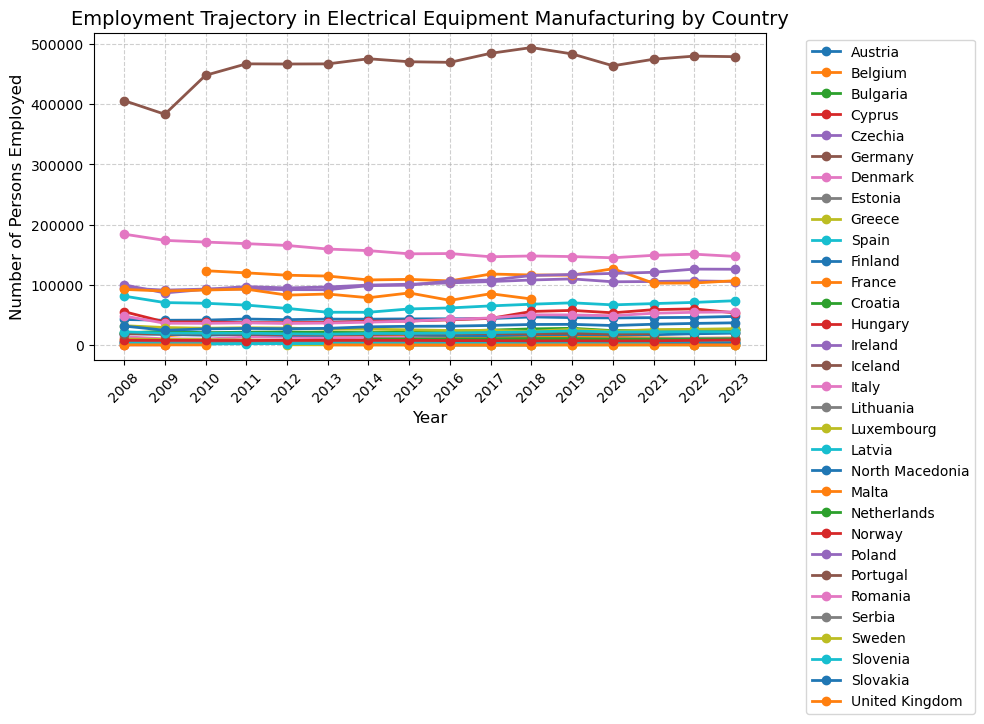

In [4]:
import matplotlib.pyplot as plt

# Filter for country-level data (NUTS 0 regions have exactly 2-letter codes)
countries_df = df_merged[df_merged['GEO_Code'].notna() & (df_merged['GEO_Code'].str.len() == 2)].copy()

# Set the index to the country label to prepare for transposing
countries_df.set_index('GEO_Label', inplace=True)

# Select only the year columns
year_cols = [col for col in countries_df.columns if str(col).isdigit()]
countries_data = countries_df[year_cols]

# Convert all values to numeric (turns remaining symbols into NaN)
countries_data = countries_data.apply(pd.to_numeric, errors='coerce')

# Transpose the dataframe: Years become the X-axis (index), Countries become the Lines (columns)
trajectory_df = countries_data.T
trajectory_df.index = trajectory_df.index.astype(int)
trajectory_df.sort_index(inplace=True)

# Generate the Line Chart
plt.figure(figsize=(10, 6))

for country in trajectory_df.columns:
    # Only plot if the country has at least one valid data point
    if trajectory_df[country].notna().any():
        plt.plot(trajectory_df.index, trajectory_df[country], marker='o', linewidth=2, label=country)

plt.title('Employment Trajectory in Electrical Equipment Manufacturing by Country', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Persons Employed', fontsize=12)
plt.xticks(trajectory_df.index, rotation=45)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('employment_trajectory.png')

Top 5 most employing countries (Average Employment):
GEO_Label  Average_Employment
  Germany       463240.125000
    Italy       157432.000000
   France       113580.428571
   Poland       106007.750000
  Czechia       101291.937500


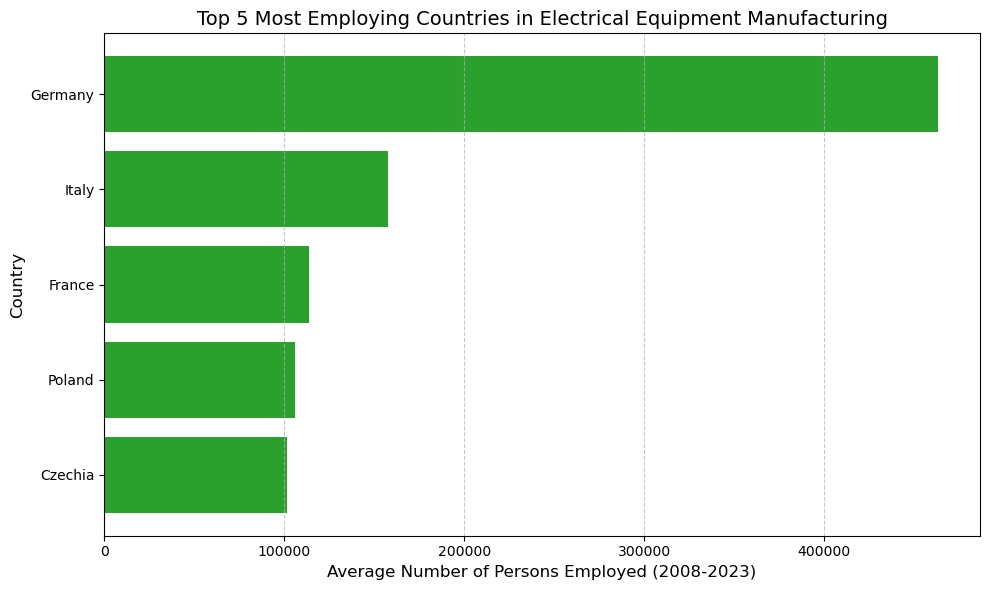

In [5]:
# Filter for country-level data (NUTS 0 regions have exactly 2-letter codes)
countries_df = df_merged[df_merged['GEO_Code'].notna() & (df_merged['GEO_Code'].str.len() == 2)].copy()

# Select only the year columns (which are all digits)
year_cols = [col for col in countries_df.columns if str(col).isdigit()]

# Convert all year columns to numeric, coercing any symbols to NaN
for col in year_cols:
    countries_df[col] = pd.to_numeric(countries_df[col], errors='coerce')

# Calculate the average employment over the available years for each country
countries_df['Average_Employment'] = countries_df[year_cols].mean(axis=1)

# Get the top 5 countries based on this historical average
top_5_countries = countries_df.nlargest(5, 'Average_Employment')

print("Top 5 most employing countries (Average Employment):")
print(top_5_countries[['GEO_Label', 'Average_Employment']].to_string(index=False))

# --- PLOTTING ---
# Sort ascending so the largest bar appears at the top of the horizontal chart
top_5_plot = top_5_countries.sort_values(by='Average_Employment', ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(top_5_plot['GEO_Label'], top_5_plot['Average_Employment'], color='#2ca02c')

# Add formatting and labels
plt.title('Top 5 Most Employing Countries in Electrical Equipment Manufacturing', fontsize=14)
plt.xlabel('Average Number of Persons Employed (2008-2023)', fontsize=12)
plt.ylabel('Country', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Ensure no labels are cut off
plt.tight_layout()

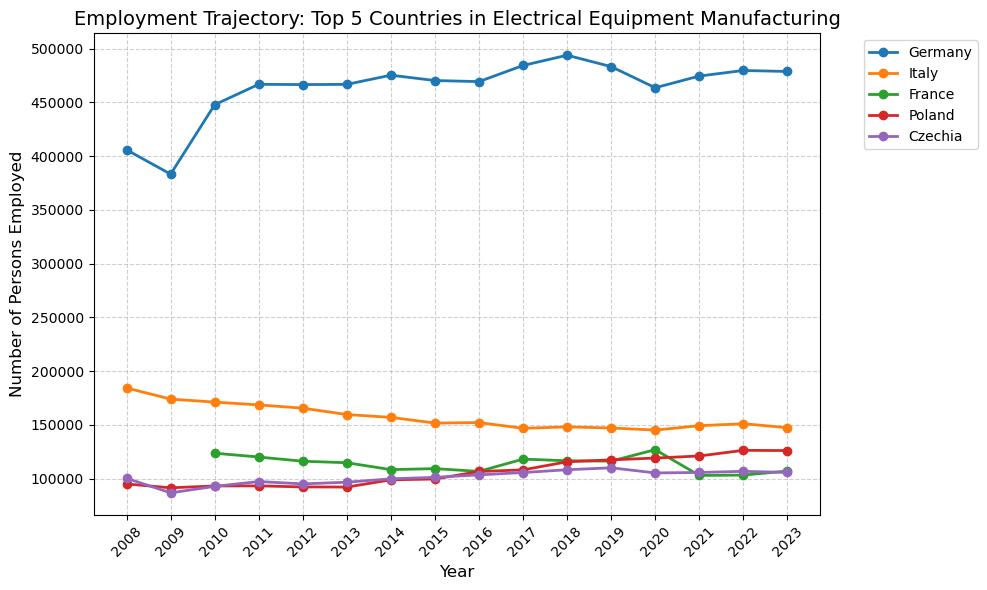

In [6]:

# Filter for country-level data
countries_df = df_merged[df_merged['GEO_Code'].notna() & (df_merged['GEO_Code'].str.len() == 2)].copy()

# Set the index to the country label
countries_df.set_index('GEO_Label', inplace=True)

# Select only the year columns
year_cols = [col for col in countries_df.columns if str(col).isdigit()]
countries_data = countries_df[year_cols]

# Convert all data to numeric values, ignoring Eurostat flags
countries_data = countries_data.apply(pd.to_numeric, errors='coerce')

# Identify the top 5 countries by average historical employment
top_5_labels = countries_data.mean(axis=1).nlargest(5).index

# Filter the dataset to ONLY include these top 5 countries
top_5_data = countries_data.loc[top_5_labels]

# Transpose the dataframe: Years become the X-axis (index), Countries become the Lines (columns)
trajectory_df = top_5_data.T
trajectory_df.index = trajectory_df.index.astype(int)
trajectory_df.sort_index(inplace=True)

# Generate the Line Chart
plt.figure(figsize=(10, 6))

# Plot a line for each of the top 5 countries
for country in trajectory_df.columns:
    plt.plot(trajectory_df.index, trajectory_df[country], marker='o', linewidth=2, label=country)

# Formatting
plt.title('Employment Trajectory: Top 5 Countries in Electrical Equipment Manufacturing', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Persons Employed', fontsize=12)
plt.xticks(trajectory_df.index, rotation=45)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()


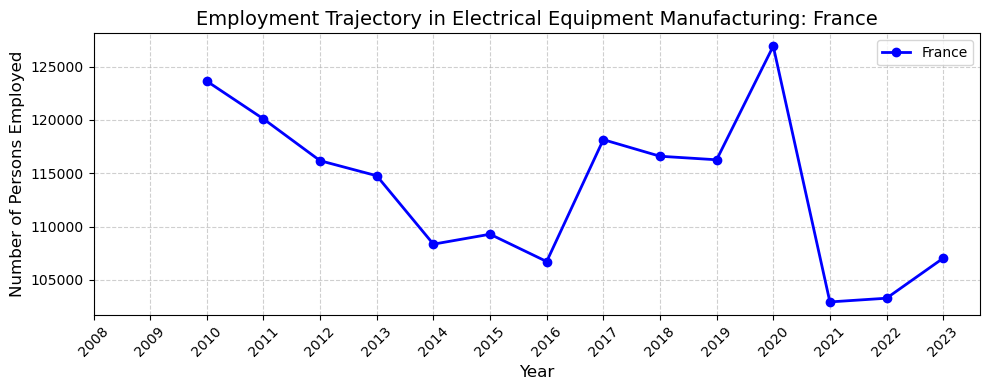

In [15]:
# Filter specifically for France (NUTS 0 code 'FR')
france_df = df_merged[df_merged['GEO_Code'] == 'FR'].copy()

# Set the index to the country label
france_df.set_index('GEO_Label', inplace=True)

# Select only the year columns (which are all digits)
year_cols = [col for col in france_df.columns if str(col).isdigit()]
france_data = france_df[year_cols]

# Convert all data to numeric values, ignoring Eurostat flags
france_data = france_data.apply(pd.to_numeric, errors='coerce')

# Transpose the dataframe: Years become the X-axis (index), Country becomes the Line (column)
trajectory_df = france_data.T
trajectory_df.index = trajectory_df.index.astype(int)
trajectory_df.sort_index(inplace=True)

# Generate the Line Chart
plt.figure(figsize=(10, 4))

# Plot the line for France
for country in trajectory_df.columns:
    plt.plot(trajectory_df.index, trajectory_df[country], marker='o', linewidth=2, color='blue', label=country)

# Formatting
plt.title('Employment Trajectory in Electrical Equipment Manufacturing: France', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Persons Employed', fontsize=12)
plt.xticks(trajectory_df.index, rotation=45)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()

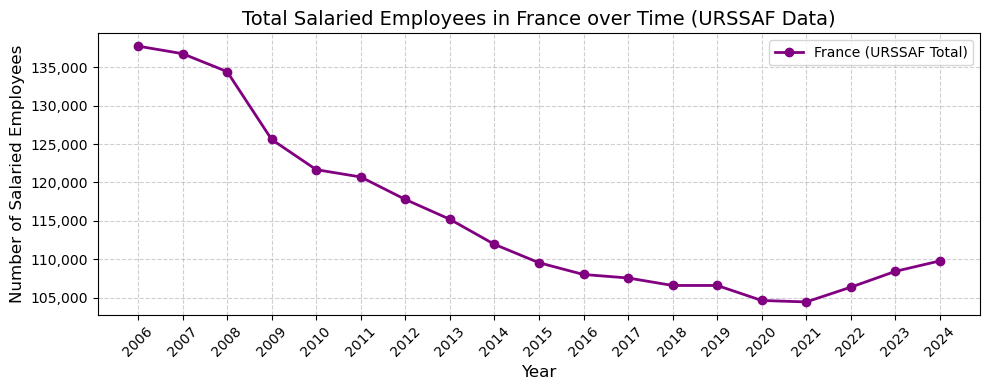

In [16]:
file_name = "../../03_data_raw/exploration_inputs/etablissements-et-effectifs-salaries-au-niveau-commune-x-ape-last (1).xlsx"
df_urssaf = pd.read_excel(file_name)

# Identify all columns that represent the number of salaried employees
effectifs_cols = [col for col in df_urssaf.columns if col.startswith('Effectifs salariés')]

years = []
totals = []

# Loop through each column, extract the year, and calculate the total sum
for col in effectifs_cols:
    year = int(col.split()[-1])
    years.append(year)
    total_emp = pd.to_numeric(df_urssaf[col], errors='coerce').sum()
    totals.append(total_emp)

# Create a clean dataframe for plotting
trajectory_df = pd.DataFrame({'Year': years, 'Total_Employees': totals})
trajectory_df.sort_values('Year', inplace=True)

# Generate the Line Chart
plt.figure(figsize=(10, 4))
plt.plot(trajectory_df['Year'], trajectory_df['Total_Employees'], marker='o', linewidth=2, color='purple', label='France (URSSAF Total)')

# Formatting
plt.title('Total Salaried Employees in France over Time (URSSAF Data)', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Salaried Employees', fontsize=12)
plt.xticks(trajectory_df['Year'], rotation=45)

# Format Y-axis with commas for readability
plt.gca().get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x)))) 

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()


In [ ]:
'../../03_data_raw/exploration_inputs/etablissements-et-effectifs-salaries-au-niveau-commune-x-ape-last.xlsx'

In [ ]:
import pandas as pd

# 1. Define file paths
file_elec = '../../03_data_raw/exploration_inputs/etablissements-et-effectifs-salaries-au-niveau-commune-x-ape-last (1).xlsx'
file_auto = '../../03_data_raw/exploration_inputs/etablissements-et-effectifs-salaries-au-niveau-commune-x-ape-last.xlsx'
# 2. Load the URSSAF datasets
df_elec = pd.read_excel(file_elec)
df_auto = pd.read_excel(file_auto)

# 3. Define the comprehensive list of target APE codes
# Edit this array if you want to add or remove any specific codes!
target_ape_codes = [
    '2720Z', 
    '2732Z', 
    '2712Z', 
    '2790Z', 
    '2711Z', 
    '2740Z'  
]

# 4. Filter the electrical dataset to only include these subsectors
df_elec_filtered = df_elec[df_elec['Code APE'].isin(target_ape_codes)].copy()

# 5. Merge (concatenate) the filtered electrical data with the automotive data
df_merged_complete = pd.concat([df_auto, df_elec_filtered], ignore_index=True)

# 6. Print verification metrics
print("--- Merge Summary ---")
print(f"Automotive rows: {len(df_auto)}")
print(f"Filtered Electrical rows (EV related): {len(df_elec_filtered)}")
print(f"Total Merged rows: {len(df_merged_complete)}")

# 7. Save the newly merged dataset
df_merged_complete.to_excel("../../03_data_raw/exploration_inputs/merged_auto_ev_electrical_complete.xlsx", index=False)
print("\nSuccess: Saved as 'merged_auto_ev_electrical_complete.xlsx'")

--- Merge Summary ---
Automotive rows: 2741
Filtered Electrical rows (EV related): 2730
Total Merged rows: 5471

Success: Saved as 'merged_auto_ev_electrical_complete.xlsx'


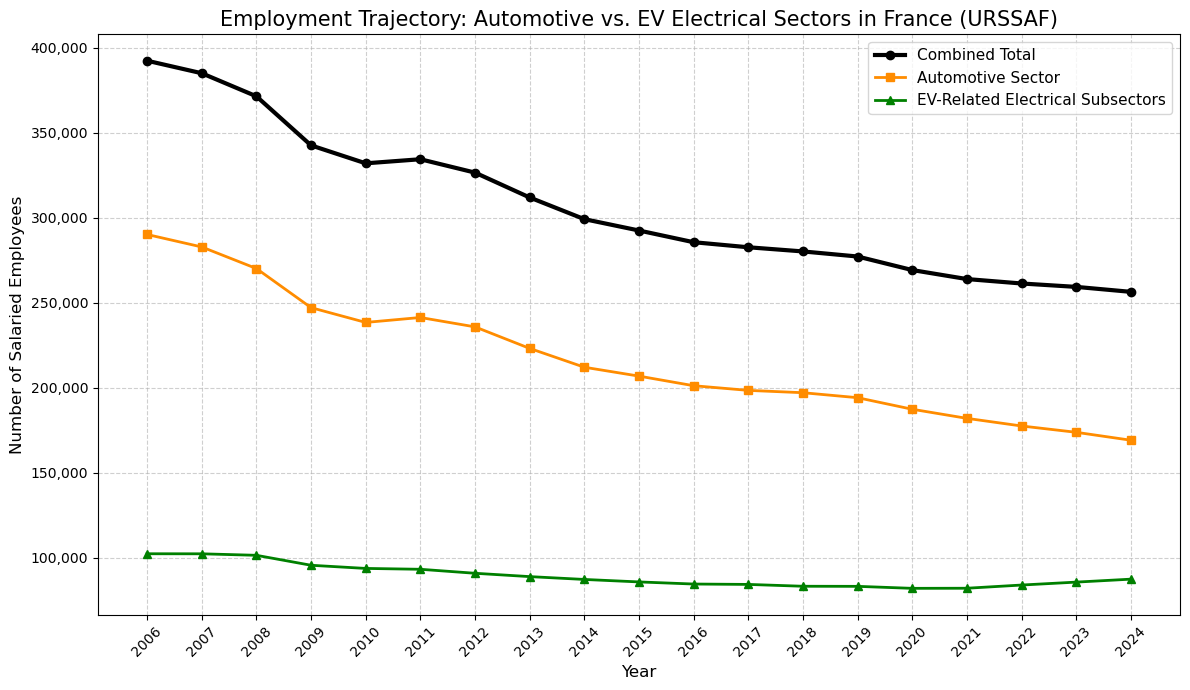

In [9]:


file_name = "../../03_data_raw/exploration_inputs/merged_auto_ev_electrical_complete.xlsx"

# Load the merged dataset
df = pd.read_excel(file_name)

# Identify all columns that represent the number of salaried employees
effectifs_cols = [col for col in df.columns if col.startswith('Effectifs salariés')]
years = [int(col.split()[-1]) for col in effectifs_cols]

# Separate the dataset into Automotive and Electrical components based on the APE code prefixes
# Automotive typically starts with '29', Electrical with '27'
df_auto = df[df['Code APE'].astype(str).str.startswith('29')]
df_elec = df[df['Code APE'].astype(str).str.startswith('27')]

# Calculate the totals per year
totals_all = []
totals_auto = []
totals_elec = []

for col in effectifs_cols:
    totals_all.append(pd.to_numeric(df[col], errors='coerce').sum())
    totals_auto.append(pd.to_numeric(df_auto[col], errors='coerce').sum())
    totals_elec.append(pd.to_numeric(df_elec[col], errors='coerce').sum())

# Create a clean dataframe for reference
trajectory_df = pd.DataFrame({
    'Year': years,
    'Total_Combined': totals_all,
    'Automotive': totals_auto,
    'EV_Electrical': totals_elec
})
trajectory_df.sort_values('Year', inplace=True)

# --- Plotting ---
plt.figure(figsize=(12, 7))

# Plot the lines
plt.plot(trajectory_df['Year'], trajectory_df['Total_Combined'], marker='o', linewidth=3, color='black', label='Combined Total')
plt.plot(trajectory_df['Year'], trajectory_df['Automotive'], marker='s', linewidth=2, color='darkorange', label='Automotive Sector')
plt.plot(trajectory_df['Year'], trajectory_df['EV_Electrical'], marker='^', linewidth=2, color='green', label='EV-Related Electrical Subsectors')

# Formatting
plt.title('Employment Trajectory: Automotive vs. EV Electrical Sectors in France (URSSAF)', fontsize=15)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Salaried Employees', fontsize=12)
plt.xticks(trajectory_df['Year'], rotation=45)

# Format Y-axis with commas for readability
plt.gca().get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x)))) 

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)

plt.tight_layout()
plt.savefig('merged_trajectory.png')

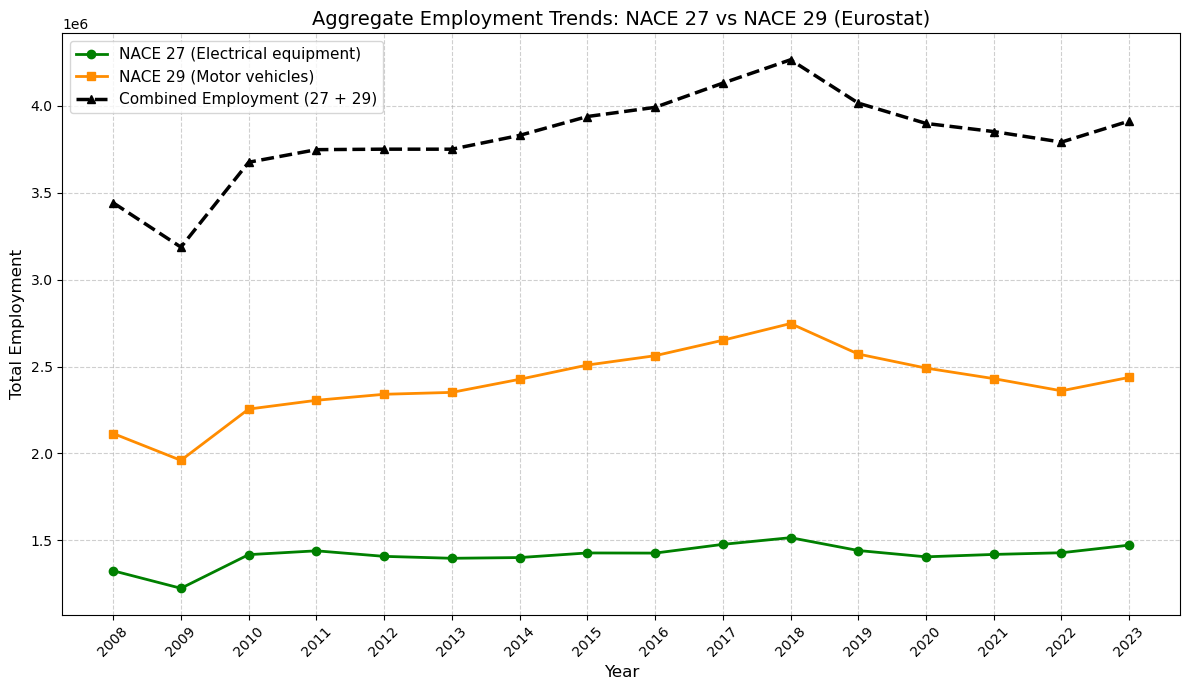

Employment in 2008:
NACE 27: 1,325,926 | NACE 29: 2,114,876 | Combined: 3,440,802

Employment in 2023:
NACE 27: 1,473,257 | NACE 29: 2,437,475 | Combined: 3,910,732


In [8]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the datasets (make sure these filenames match your local files)
df_27 = pd.read_excel('../../03_data_raw/exploration_inputs/merged_employment_nace_27.xlsx')
df_29_emp = pd.read_excel('../../03_data_raw/exploration_inputs/merged_employment_nace_29.xlsx', sheet_name="Employment_Merged")

# 2. Standardize NACE 29 columns by keeping only the years (dropping the Eurostat flags)
years = [str(y) for y in range(2008, 2024)]
cols_to_keep_29 = ['GEO code', 'GEO label'] + years
df_29 = df_29_emp[cols_to_keep_29].copy()

# Rename columns to match the NACE 27 dataset for a seamless merge
df_29.rename(columns={'GEO code': 'GEO_Code', 'GEO label': 'GEO_Label'}, inplace=True)

# 3. Convert year columns to numeric, coercing ':' (missing values) to NaN
for y in years:
    df_27[y] = pd.to_numeric(df_27[y], errors='coerce')
    df_29[y] = pd.to_numeric(df_29[y], errors='coerce')

# 4. Merge the datasets on the geographic identifiers
merged_df = pd.merge(df_27, df_29, on=['GEO_Code', 'GEO_Label'], suffixes=('_NACE27', '_NACE29'))

# 5. Filter for Country Level (NUTS 0) to avoid double-counting sub-regions
# Country codes in NUTS have a length of 2 (e.g., 'FR', 'DE', 'AT')
country_df = merged_df[merged_df['GEO_Code'].str.len() == 2].copy()

# 6. Calculate total employment per year across these countries
nace27_totals = country_df[[f"{y}_NACE27" for y in years]].sum().values
nace29_totals = country_df[[f"{y}_NACE29" for y in years]].sum().values
combined_totals = nace27_totals + nace29_totals

# 7. Plotting the trends
plt.figure(figsize=(12, 7))

# Plot NACE 27, NACE 29, and the Combined total
plt.plot(years, nace27_totals, marker='o', linewidth=2, color='green', label='NACE 27 (Electrical equipment)')
plt.plot(years, nace29_totals, marker='s', linewidth=2, color='darkorange', label='NACE 29 (Motor vehicles)')
plt.plot(years, combined_totals, marker='^', linestyle='--', color='black', linewidth=2.5, label='Combined Employment (27 + 29)')

# Formatting the chart
plt.title('Aggregate Employment Trends: NACE 27 vs NACE 29 (Eurostat)', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Total Employment', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()

# 8. Save the outputs
plt.savefig('employment_trends_comparison.png')
merged_df.to_csv('merged_employment_27_and_29.csv', index=False)

# Display the plot in your environment
plt.show()

# 9. Print summary statistics
print("Employment in 2008:")
print(f"NACE 27: {nace27_totals[0]:,.0f} | NACE 29: {nace29_totals[0]:,.0f} | Combined: {combined_totals[0]:,.0f}")
print("\nEmployment in 2023:")
print(f"NACE 27: {nace27_totals[-1]:,.0f} | NACE 29: {nace29_totals[-1]:,.0f} | Combined: {combined_totals[-1]:,.0f}")